# From Messy to Meaningful: Cleaning, Transforming and Visualising Cape Town Airbnb Data

**ICE262S Data Science – Integrated Assignment (Python demonstration)**

This notebook walks through three consecutive stages of the Data Science Pipeline on one real dataset:

1. **Data Cleaning** – detecting and correcting (or removing) inaccurate, incomplete or irrelevant records
2. **Data Transformation** – converting cleaned data into a format suited to analysis (feature engineering, encoding, scaling)
3. **Data Exploration & Visualisation** – summarising the data and turning it into charts that reveal patterns, trends and outliers

**Dataset:** Inside Airbnb – Cape Town, Western Cape, South Africa, detailed listings (`listings.csv.gz`), scraped 25–27 September 2026.
Source: insideairbnb.com/get-the-data · Licence: Creative Commons Attribution 4.0 (CC BY 4.0).

**How to run:** put `listings.csv.gz` in the same folder as this notebook, then run the cells from top to bottom (Kernel → Restart & Run All).

## 0. Setup

In [1]:
# Core libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

DATA_PATH = "listings.csv.gz"      # pandas reads .gz files directly – no need to unzip
CHART_DIR = "charts"               # every chart is also saved here for the slides and video
os.makedirs(CHART_DIR, exist_ok=True)

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | seaborn 0.13.2


---
# PART 1 – DATA CLEANING

> **Data cleaning** is the process of detecting and correcting (or removing) inaccurate, incomplete or irrelevant records from a dataset. *Garbage in, garbage out.*

Our steps: **Import → Inspect → Drop empty columns → Remove duplicates → Fix structural errors → Handle missing values → Handle outliers → Validate & export.**

### Step 1 – Import the raw data

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", raw.shape)
raw.head(3)

Shape (rows, columns): (27760, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,...,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,15007,https://www.airbnb.com/rooms/15007,20260923225056,2026-09-26,previous scrape,Blaauwberg House on the beach in Bloubergstrand,Welcome to our self-catering beach-front famil...,NaN,https://a0.muscache.com/pictures/3b654aa4-248e...,59072,https://www.airbnb.com/users/show/59072,1462507936690024262,https://www.airbnb.com/users/profile/146250793...,Dirk,NaN,...,2026-03-16,4.83,4.91,4.83,4.98,4.94,4.94,4.85,NaN,NaN,2,2,0,0,0.34
1,15077,https://www.airbnb.com/rooms/15077,20260923225056,2026-09-26,NaN,Superior Room | 100m to Sunset Beach | Cape Town,Our Superior Rooms (approx. 25 m²) offer a rel...,NaN,https://a0.muscache.com/pictures/4a8fceaa-655e...,59342,https://www.airbnb.com/users/show/59342,1462507943957675735,https://www.airbnb.com/users/profile/146250794...,Georg,NaN,...,2022-06-16,5.00,4.86,4.86,4.86,4.71,4.86,5.00,NaN,NaN,6,2,4,0,0.04
2,15199,https://www.airbnb.com/rooms/15199,20260923225056,2026-09-26,NaN,Self catering apartment,<b>The space</b><br />Amenities :<br />Welcome...,NaN,https://a0.muscache.com/pictures/142776/5b6c9e...,59694,https://www.airbnb.com/users/show/59694,1462507955227049701,https://www.airbnb.com/users/profile/146250795...,Alexa,NaN,...,2016-04-15,4.50,4.00,4.00,4.50,5.00,5.00,4.00,NaN,NaN,1,1,0,0,0.01


### Step 2 – Inspect before changing anything
Never skip this step. We look at data types, missing values and a few columns we care about.

In [3]:
# Which columns are completely or mostly empty?
missing_pct = (raw.isnull().sum() / len(raw) * 100).sort_values(ascending=False)
print("Columns that are 100% empty:", (missing_pct == 100).sum())
missing_pct.head(20).round(1)

Columns that are 100% empty: 14


neighborhood_overview           100.0
host_since                      100.0
host_response_time              100.0
host_thumbnail_url              100.0
host_acceptance_rate            100.0
host_response_rate              100.0
host_verifications              100.0
neighbourhood                   100.0
host_total_listings_count       100.0
host_neighbourhood              100.0
calendar_updated                100.0
instant_bookable                100.0
neighbourhood_group_cleansed    100.0
bathrooms                       100.0
license                          99.4
source                           89.1
host_about                       46.6
host_location                    26.6
review_scores_checkin            19.9
review_scores_value              19.9
dtype: float64

In [4]:
# The price column looks numeric, but it is stored as TEXT with '$' and ',' symbols
print("Data type of price:", raw["price"].dtype)
raw[["name", "price", "bathrooms_text", "host_is_superhost"]].head(8)

Data type of price: str


,name,price,bathrooms_text,host_is_superhost
0,Blaauwberg House on the beach in Bloubergstrand,NaN,2 baths,f
1,Superior Room | 100m to Sunset Beach | Cape Town,"$1,114.00",1 private bath,f
2,Self catering apartment,"$2,275.00",1 bath,f
3,In hip designer district of Cape T.,$507.69,1 bath,f
4,Hollywood Mansion & Spa Camps Bay with Butler,"$36,500.00",7.5 baths,f
5,"idyllic private Cottage, cleaning weekdays incl.","$1,757.00",1 bath,t
6,Largo House self catering suite,$881.00,1 bath,t
7,Fabulous views,$910.75,1 private bath,t


**What the inspection reveals:**
- Many columns are 100% empty and carry no information.
- `price` is text (`"$1,114.00"`), so we cannot calculate with it. The `$` sign is also misleading: the raw price quotes show the currency is **ZAR (rand)**.
- `bathrooms_text` mixes numbers and words (`"1.5 shared baths"`, `"Half-bath"`).
- `host_is_superhost` uses `"t"`/`"f"` instead of True/False.

### Step 3 – Drop irrelevant and empty columns

In [5]:
# Drop columns that are more than 50% empty (as in our course notes)
df = raw.dropna(thresh=len(raw) * 0.5, axis=1)
print("Columns before:", raw.shape[1], "→ after dropping mostly-empty columns:", df.shape[1])

# Keep only the columns relevant to our analysis (removes URLs, long text, scrape metadata)
keep = [
    "id", "name", "host_id", "host_is_superhost", "calculated_host_listings_count",
    "neighbourhood_cleansed", "latitude", "longitude", "property_type", "room_type",
    "accommodates", "bathrooms_text", "bedrooms", "beds", "price",
    "minimum_nights", "availability_365", "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "estimated_occupancy_l365d", "estimated_revenue_l365d",
]
df = df[keep].copy()
df = df.rename(columns={"neighbourhood_cleansed": "ward"})
print("Columns kept for analysis:", df.shape[1])

Columns before: 90 → after dropping mostly-empty columns: 74
Columns kept for analysis: 22


### Step 4 – Remove duplicate records
Exact duplicate rows are rare in scraped data, but the **same property can be listed twice** by one host. We check both.

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())

# Same host + same listing name + same exact location = the same property listed twice
dup_mask = df.duplicated(subset=["host_id", "name", "latitude", "longitude"])
print("Same property listed more than once:", dup_mask.sum())

df = df.drop_duplicates(subset=["host_id", "name", "latitude", "longitude"], keep="first")
print("Rows after removing duplicates:", len(df))

Exact duplicate rows: 0
Same property listed more than once: 47
Rows after removing duplicates: 27713


### Step 5 – Fix structural errors (wrong data types and inconsistent formats)

In [7]:
# 5a. price: text "$1,114.00" → number 1114.0  (values are in rand)
df["price_zar"] = pd.to_numeric(
    df["price"].str.replace(r"[$,]", "", regex=True), errors="coerce"
)
df = df.drop(columns="price")

# 5b. bathrooms_text: "1.5 shared baths" → 1.5, "Half-bath" → 0.5, plus a shared/private flag
df["bathrooms"] = pd.to_numeric(
    df["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0], errors="coerce"
)
df.loc[df["bathrooms_text"].str.contains("half", case=False, na=False), "bathrooms"] = 0.5
df["shared_bath"] = df["bathrooms_text"].str.contains("shared", case=False, na=False)
df = df.drop(columns="bathrooms_text")

# 5c. superhost: "t"/"f" → True/False
df["host_is_superhost"] = df["host_is_superhost"].map({"t": True, "f": False})

df[["price_zar", "bathrooms", "shared_bath", "host_is_superhost"]].head()

,price_zar,bathrooms,shared_bath,host_is_superhost
0,NaN,2.0,False,False
1,1114.00,1.0,False,False
2,2275.00,1.0,False,False
3,507.69,1.0,False,False
4,36500.00,7.5,False,False


### Step 6 – Handle missing values
There is no single right answer: the strategy depends on **why** a value is missing.

In [8]:
df.isnull().sum()[df.isnull().sum() > 0]

name                          1
bedrooms                     22
beds                        400
minimum_nights                1
reviews_per_month          5490
review_scores_rating       5490
estimated_revenue_l365d    2807
price_zar                  2807
bathrooms                   357
dtype: int64

In [9]:
# (a) No price = the listing had no bookable price when scraped. Price is central to our
#     analysis, so these rows are dropped rather than guessed.
before = len(df)
df = df.dropna(subset=["price_zar"])
print("Dropped listings with no price:", before - len(df))

# (b) reviews_per_month is missing because the listing has NO reviews → the true value is 0,
#     not the mean. Context decides the fill value.
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

# (c) review_scores_rating is missing for unreviewed listings. We keep a flag, then fill with the median.
df["has_reviews"] = df["number_of_reviews"] > 0
df["review_scores_rating"] = df["review_scores_rating"].fillna(df["review_scores_rating"].median())

# (d) A few listings miss bedrooms/beds/bathrooms → fill with the median (robust to outliers)
for col in ["bedrooms", "beds", "bathrooms"]:
    df[col] = df[col].fillna(df[col].median())

# (e) One listing has no minimum stay (critical field → drop) and one has no name (→ placeholder text)
df = df.dropna(subset=["minimum_nights"])
df["name"] = df["name"].fillna("Unnamed listing")

print("Missing values left:", df.isnull().sum().sum())

Dropped listings with no price: 2807


Missing values left: 0


### Step 7 – Handle outliers: investigate before removing
Our notes give the **IQR rule**: values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR are flagged as outliers. Let's see what it flags.

In [10]:
q1, q3 = df["price_zar"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
flagged = df[df["price_zar"] > upper_fence]
print(f"Q1 = R{q1:,.0f} | Q3 = R{q3:,.0f} | IQR = R{iqr:,.0f} | upper fence = R{upper_fence:,.0f}")
print(f"IQR rule flags {len(flagged):,} listings ({len(flagged)/len(df):.1%} of the data)")

# What are the most expensive listings? Errors, or real?
flagged.sort_values("price_zar", ascending=False)[["name", "room_type", "accommodates", "price_zar"]].head(8)

Q1 = R1,238 | Q3 = R3,553 | IQR = R2,314 | upper fence = R7,025
IQR rule flags 2,678 listings (10.8% of the data)


,name,room_type,accommodates,price_zar
20996,Quilla Quarters,Entire home/apt,2,975000.00
14164,Tamboerskloof Treat 4BR House,Entire home/apt,8,381518.00
4312,Obsidian,Entire home/apt,10,192183.33
27318,Springbok Villa,Entire home/apt,6,171764.00
17988,JRS_Airbnbリスティング_B,Entire home/apt,1,158826.00
3814,21 Nettleton 6 bedroom villa,Entire home/apt,16,154770.00
12030,Luxury Villa Cape Town • Views • Staffed 252,Entire home/apt,10,145761.14
5053,Villa St. Leger,Entire home/apt,10,145000.00


**Investigation result:** the IQR rule flags over 10% of listings, and most of them are genuine. Cape Town has a real luxury market of villas sleeping 8–16 guests.
But some prices are clearly impossible: a 2-guest flat at R975,000 a night, and several studio flats at exactly R100,000 (a placeholder hosts use to block bookings).

A fairer test is **price per guest**: a villa for 10 at R150,000 is R15,000 per person, while a studio for 2 at R100,000 is R50,000 per person.

In [11]:
df["price_per_guest"] = df["price_zar"] / df["accommodates"]
df.sort_values("price_per_guest", ascending=False)[
    ["name", "property_type", "accommodates", "price_zar", "price_per_guest"]
].head(12)

,name,property_type,accommodates,price_zar,price_per_guest
20996,Quilla Quarters,Entire rental unit,2,975000.0,487500.000000
17988,JRS_Airbnbリスティング_B,Entire rental unit,1,158826.0,158826.000000
24391,Executive King Suite,Room in boutique hotel,2,122200.0,61100.000000
18987,Stylish Studio Apartment in City Centre,Entire rental unit,2,100000.0,50000.000000
19002,One-bed Apartment in Lively Loop Street,Entire rental unit,2,100000.0,50000.000000
18920,Fully-Fitted One-Bed Apartment with Mountain V...,Entire rental unit,2,100000.0,50000.000000
18916,Centerally located Executive Studio Apartment,Entire rental unit,2,100000.0,50000.000000
18919,One-Bed Apartment with Stunning Views,Entire rental unit,2,100000.0,50000.000000
18918,Spacious Studio Apartment in City Centre,Entire rental unit,2,100000.0,50000.000000
14164,Tamboerskloof Treat 4BR House,Entire home,8,381518.0,47689.750000


**Decision (a documented judgement call):**
- **Remove** implausible prices: more than **R20,000 per guest per night**.
- **Remove** invalid stays: minimum stay over 365 nights.
- **Keep** genuine luxury listings in the clean dataset.
- For charts of the *typical* market, use a separate `typical` subset inside the IQR fences, so the shape of the data stays readable.

In [12]:
before = len(df)
df = df[df["price_per_guest"] <= 20000]
print("Removed implausible prices (> R20,000 per guest):", before - len(df))

before = len(df)
df = df[df["minimum_nights"] <= 365]
print("Removed listings with minimum stay > 365 nights:", before - len(df))

typical = df[df["price_zar"].between(q1 - 1.5 * iqr, upper_fence)].copy()
print(f"Clean dataset: {len(df):,} listings | 'typical' subset for distribution charts: {len(typical):,}")

Removed implausible prices (> R20,000 per guest): 17
Removed listings with minimum stay > 365 nights: 0
Clean dataset: 24,888 listings | 'typical' subset for distribution charts: 22,227


### Step 8 – Validate and export the clean dataset

In [13]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate properties:", df.duplicated(subset=["host_id", "name", "latitude", "longitude"]).sum())
print("Price range: R{:,.0f} – R{:,.0f}".format(df["price_zar"].min(), df["price_zar"].max()))
print(df.dtypes.value_counts())

# Always save to a NEW file – never overwrite the raw data (audit trail)
df.to_csv("cape_town_listings_clean.csv", index=False)
print("Saved cape_town_listings_clean.csv")

Shape: (24888, 25)
Missing values: 0
Duplicate properties: 0
Price range: R127 – R192,183
float64    11
int64       7
str         4
bool        3
Name: count, dtype: int64


Saved cape_town_listings_clean.csv


---
# PART 2 – DATA TRANSFORMATION

> **Data transformation** is the process of converting raw data into a suitable format that supports efficient data mining and retrieval of strategic information.

We apply three techniques from our notes: **feature engineering**, **encoding** and **scaling**.

### 2.1 Feature engineering – create new, meaningful columns

In [14]:
tdf = df.copy()

# Price per guest (first created while investigating outliers) makes a 2-sleeper and a 10-sleeper comparable
tdf["price_per_guest"] = tdf["price_zar"] / tdf["accommodates"]

# Commercial vs individual hosts: a host with more than one listing runs it as a business
tdf["multi_listing_host"] = tdf["calculated_host_listings_count"] > 1

# Guest capacity bands (an ORDERED category)
tdf["size_band"] = pd.cut(
    tdf["accommodates"], bins=[0, 2, 4, 6, 100],
    labels=["1-2 guests", "3-4 guests", "5-6 guests", "7+ guests"]
)

tdf[["price_zar", "accommodates", "price_per_guest", "calculated_host_listings_count",
     "multi_listing_host", "size_band"]].head()

,price_zar,accommodates,price_per_guest,calculated_host_listings_count,multi_listing_host,size_band
1,1114.00,2,557.000000,6,True,1-2 guests
2,2275.00,2,1137.500000,1,False,1-2 guests
3,507.69,2,253.845000,1,False,1-2 guests
4,36500.00,15,2433.333333,4,True,7+ guests
5,1757.00,2,878.500000,3,True,1-2 guests


### 2.2 Encoding – turn text categories into numbers
- **Nominal** categories (no order, e.g. room type) → **one-hot encoding**
- **Ordinal** categories (a real order, e.g. size band) → **label/ordinal encoding**

In [15]:
# One-hot encode room_type (nominal): one 0/1 column per category
tdf = pd.get_dummies(tdf, columns=["room_type"], prefix="room", dtype=int)
print([c for c in tdf.columns if c.startswith("room_")])

# Ordinal encode size_band: the numbers keep the order 0 < 1 < 2 < 3
size_order = {"1-2 guests": 0, "3-4 guests": 1, "5-6 guests": 2, "7+ guests": 3}
tdf["size_band_code"] = tdf["size_band"].astype(str).map(size_order)

# Booleans → 1/0
for col in ["host_is_superhost", "multi_listing_host", "shared_bath", "has_reviews"]:
    tdf[col] = tdf[col].astype(int)

tdf[["size_band", "size_band_code", "host_is_superhost", "multi_listing_host"]].head()

['room_Entire home/apt', 'room_Hotel room', 'room_Private room', 'room_Shared room']


,size_band,size_band_code,host_is_superhost,multi_listing_host
1,1-2 guests,0,0,1
2,1-2 guests,0,0,0
3,1-2 guests,0,0,0
4,7+ guests,3,0,1
5,1-2 guests,0,1,1


### 2.3 Scaling – put numeric features on a comparable scale
Price is in the thousands, guests are single digits. Without scaling, price would dominate any distance-based model.
We compare three scalers on the same columns.

In [16]:
num_cols = ["price_zar", "accommodates", "availability_365", "number_of_reviews"]

minmax = MinMaxScaler().fit_transform(tdf[num_cols])        # squeezes to [0, 1]
standard = StandardScaler().fit_transform(tdf[num_cols])    # mean 0, std 1
robust = RobustScaler().fit_transform(tdf[num_cols])        # uses median and IQR

compare = pd.DataFrame({
    "original price (R)": tdf["price_zar"].describe(),
    "MinMax price": pd.Series(minmax[:, 0]).describe(),
    "Standard price": pd.Series(standard[:, 0]).describe(),
    "Robust price": pd.Series(robust[:, 0]).describe(),
})
compare.round(3)

,original price (R),MinMax price,Standard price,Robust price
count,24888.000,24888.000,24888.000,24888.000
mean,3640.679,0.018,0.000,0.750
std,6440.613,0.034,1.000,2.788
min,126.960,0.000,-0.546,-0.771
25%,1237.500,0.006,-0.373,-0.290
50%,1907.585,0.009,-0.269,0.000
75%,3547.500,0.018,-0.014,0.710
max,192183.330,1.000,29.275,82.370


**Interpretation:** with MinMax scaling, the single most expensive villa becomes 1.0 and squeezes almost every other listing into a tiny band near 0 (look at the median).
This is the **outlier sensitivity** our notes warn about. **RobustScaler** (median and IQR) is the better choice for price.

*Note on data leakage:* when a model is trained later, the scaler must be fitted on the training set only and then applied to the test set.

In [17]:
tdf[[c + "_scaled" for c in num_cols]] = robust
print("Final transformed shape:", tdf.shape)
tdf.to_csv("cape_town_listings_transformed.csv", index=False)

Final transformed shape: (24888, 35)


---
# PART 3 – DATA EXPLORATION & VISUALISATION

> Visualisation transforms data into charts that reveal patterns, trends, relationships and outliers, for technical and non-technical audiences alike.

We start with descriptive statistics, then chart the findings.

### 3.1 Descriptive statistics

In [18]:
p = df["price_zar"]
print(f"Listings: {len(df):,}")
print(f"Mean price:   R{p.mean():,.0f}")
print(f"Median price: R{p.median():,.0f}")
print(f"Std dev:      R{p.std():,.0f}")
print(f"Skewness:     {p.skew():.1f}  (positive = long tail to the right)")

Listings: 24,888
Mean price:   R3,641
Median price: R1,908
Std dev:      R6,441
Skewness:     9.0  (positive = long tail to the right)


The **mean is far above the median**, so prices are **skewed right**: a few very expensive villas pull the mean up.
For a 'typical' Cape Town nightly price, the **median** is the better measure.

### 3.2 Before vs after cleaning – why cleaning matters

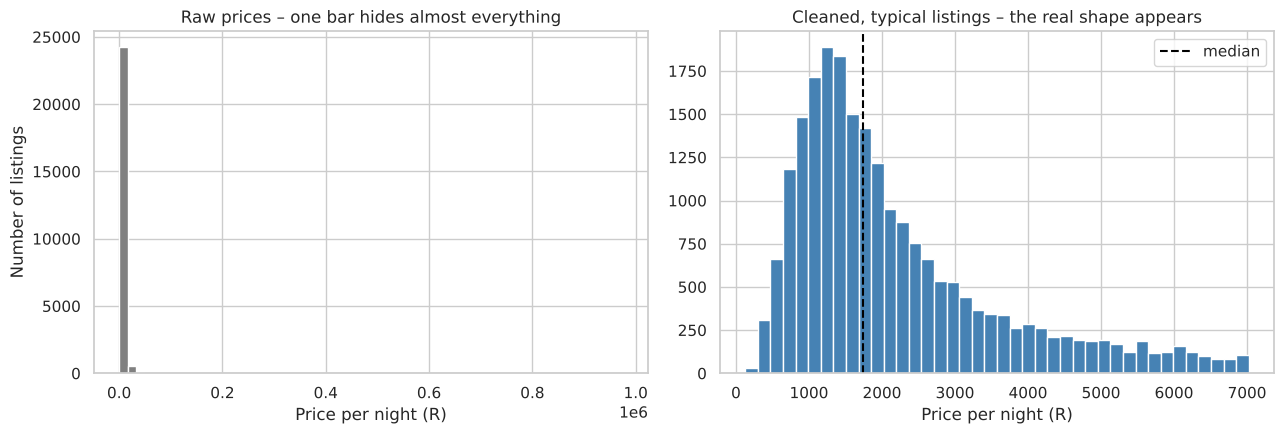

In [19]:
raw_price = pd.to_numeric(raw["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(raw_price.dropna(), bins=60, color="grey")
axes[0].set_title("Raw prices – one bar hides almost everything")
axes[0].set_xlabel("Price per night (R)")
axes[0].set_ylabel("Number of listings")

axes[1].hist(typical["price_zar"], bins=40, color="steelblue")
axes[1].axvline(typical["price_zar"].median(), color="black", linestyle="--", label="median")
axes[1].set_title("Cleaned, typical listings – the real shape appears")
axes[1].set_xlabel("Price per night (R)")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/01_price_before_after.png", dpi=150)
plt.show()

### 3.3 Price by room type (box plot)

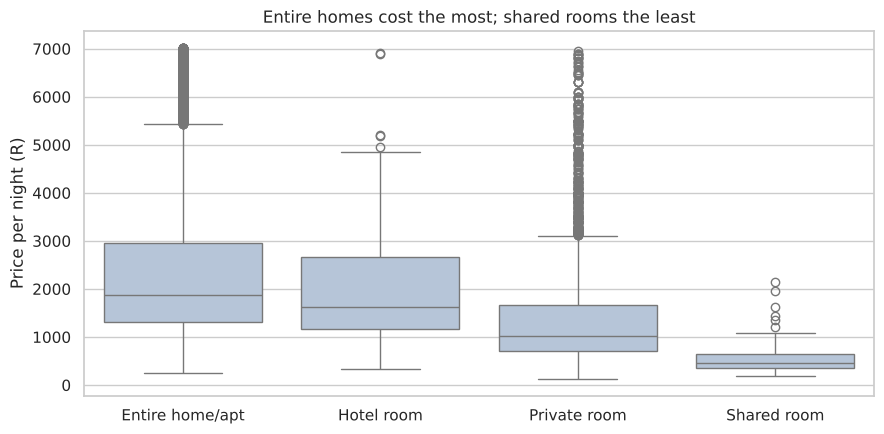

,count,median
room_type,,
Entire home/apt,20981,2095.50
Private room,3773,1050.00
Hotel room,78,1670.00
Shared room,56,450.75


In [20]:
order = df.groupby("room_type")["price_zar"].median().sort_values(ascending=False).index
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=typical, x="room_type", y="price_zar", order=order, color="lightsteelblue")
plt.title("Entire homes cost the most; shared rooms the least")
plt.xlabel("")
plt.ylabel("Price per night (R)")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/02_price_by_room_type.png", dpi=150)
plt.show()

df.groupby("room_type")["price_zar"].agg(["count", "median"]).sort_values("count", ascending=False)

### 3.4 Where are the listings? Top 10 wards

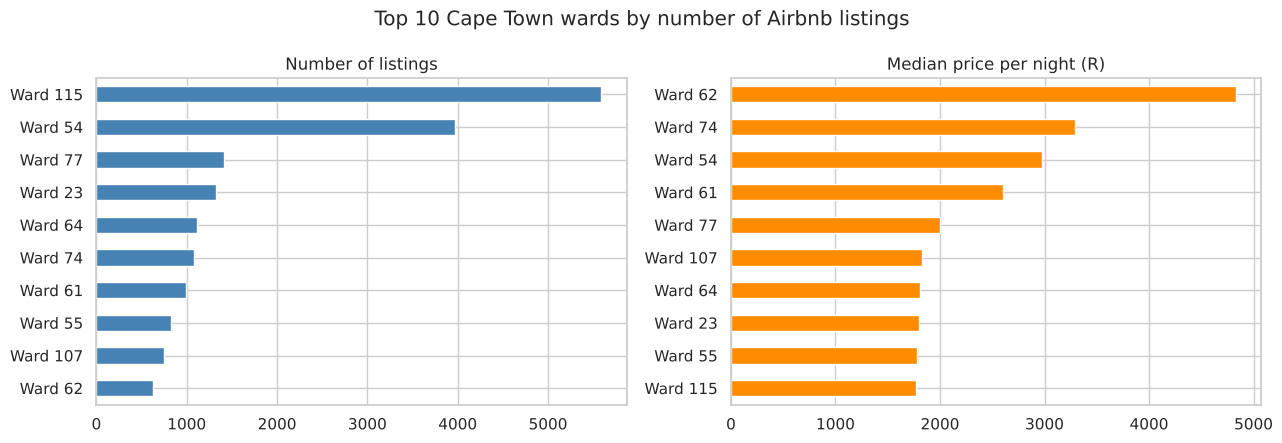

,listings,median_price
ward,,
Ward 115,5590,1766.665
Ward 54,3974,2976.260
Ward 77,1414,2000.000
Ward 23,1322,1800.000
Ward 64,1117,1809.000
Ward 74,1077,3290.000
Ward 61,992,2600.000
Ward 55,827,1782.500
Ward 107,753,1825.000


In [21]:
ward_stats = (df.groupby("ward")
                .agg(listings=("id", "count"), median_price=("price_zar", "median"))
                .sort_values("listings", ascending=False)
                .head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ward_stats["listings"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Number of listings")
axes[0].set_ylabel("")
ward_stats["median_price"].sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Median price per night (R)")
axes[1].set_ylabel("")
plt.suptitle("Top 10 Cape Town wards by number of Airbnb listings")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/03_top_wards.png", dpi=150)
plt.show()
ward_stats

### 3.5 A map made from data – latitude and longitude

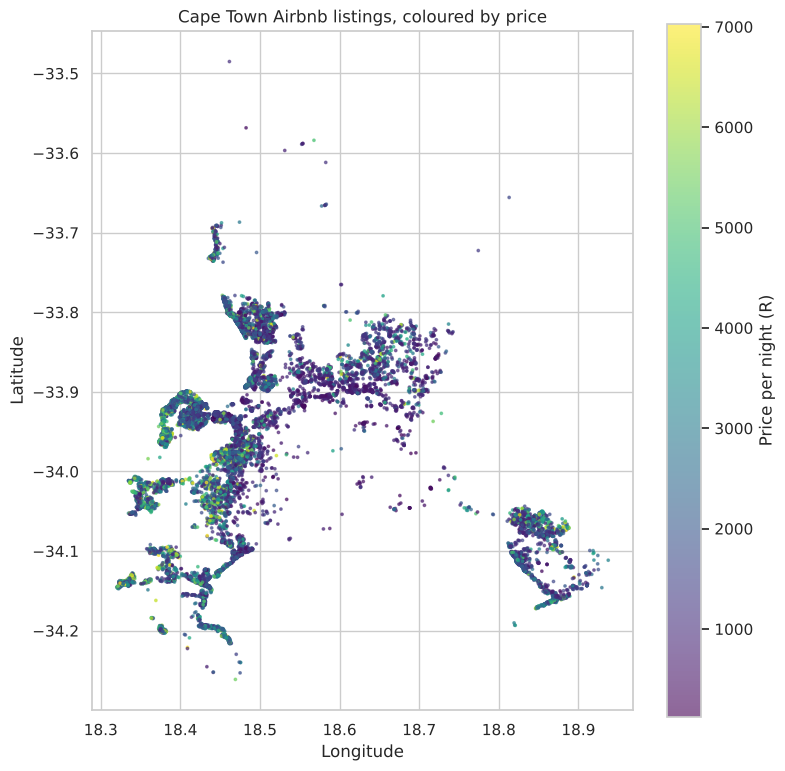

In [22]:
plt.figure(figsize=(8, 8))
sc = plt.scatter(typical["longitude"], typical["latitude"], c=typical["price_zar"],
                 cmap="viridis", s=3, alpha=0.6)
plt.colorbar(sc, label="Price per night (R)")
plt.title("Cape Town Airbnb listings, coloured by price")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/04_listing_map.png", dpi=150)
plt.show()

### 3.6 Correlation heatmap

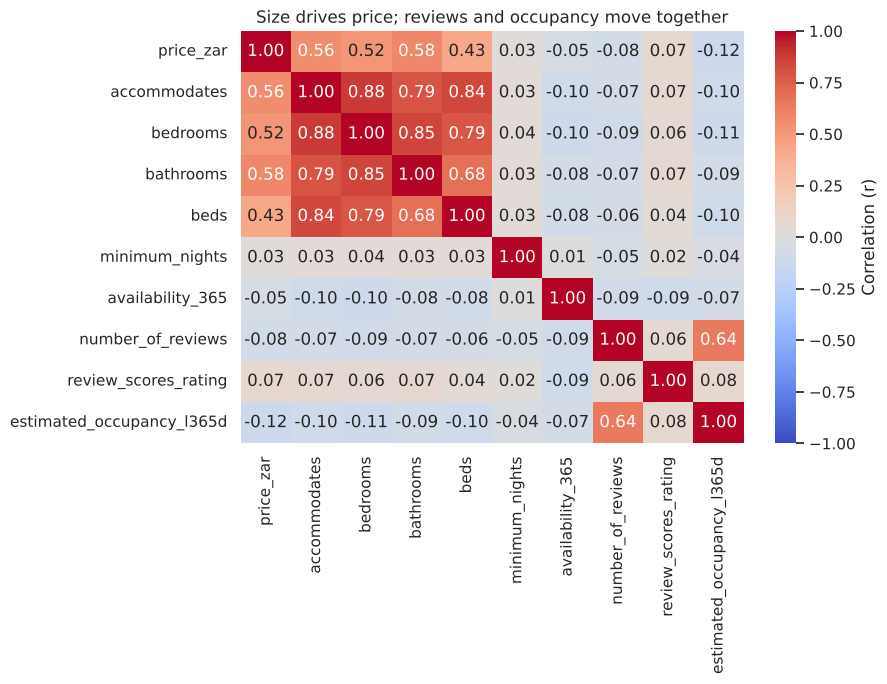

In [23]:
heat_cols = ["price_zar", "accommodates", "bedrooms", "bathrooms", "beds",
             "minimum_nights", "availability_365", "number_of_reviews",
             "review_scores_rating", "estimated_occupancy_l365d"]
corr = df[heat_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            cbar_kws={"label": "Correlation (r)"})
plt.title("Size drives price; reviews and occupancy move together")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/05_correlation_heatmap.png", dpi=150)
plt.show()

### 3.7 Who are the hosts? Individuals vs commercial operators

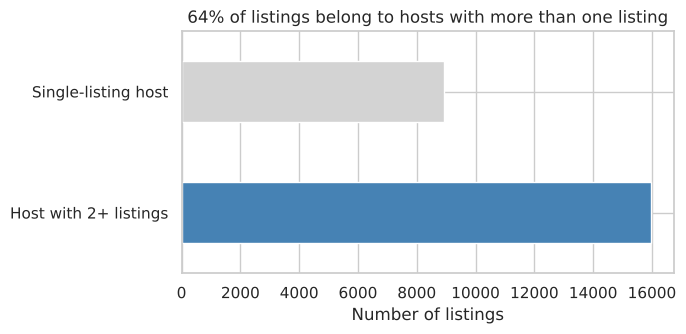

multi_listing_host
Host with 2+ listings    15951
Single-listing host       8937
Name: count, dtype: int64

In [24]:
host_share = tdf["multi_listing_host"].map({1: "Host with 2+ listings", 0: "Single-listing host"}).value_counts()

plt.figure(figsize=(7, 3.5))
host_share.plot.barh(color=["steelblue", "lightgrey"])
plt.title(f"{host_share.iloc[0] / host_share.sum():.0%} of listings belong to hosts with more than one listing")
plt.xlabel("Number of listings")
plt.ylabel("")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/06_host_types.png", dpi=150)
plt.show()
host_share

---
# Summary of findings

**What cleaning did** (27,760 raw listings × 90 columns → 24,888 clean listings × 25 columns):
- Dropped 14 completely empty columns and 50+ irrelevant ones (URLs, long text, scrape metadata).
- Removed 47 properties listed twice by the same host.
- Converted `price` from text to numbers, and found it is in **rand**, despite the `$` sign.
- Dropped 2,807 listings with no price; filled missing review rates with 0, because no reviews means zero, not the average.
- Investigated outliers: the IQR rule would have deleted 10.8% of genuine listings, so we removed only 17 implausible prices (over R20,000 per guest per night).

**What the data shows about Cape Town's Airbnb market (September 2026):**
1. **A typical night costs about R1,900.** The median is R1,908, but the mean is R3,641 because luxury villas pull it up (right-skewed data).
2. **Entire homes dominate:** 84% of listings, at a median of about R2,100 a night, against R1,050 for a private room.
3. **Listings are concentrated:** Ward 115 (City Centre / Green Point) alone holds about 5,600 listings, over a fifth of the city's total.
4. **Size drives price:** price correlates most with bathrooms (r = 0.58), guest capacity (0.56) and bedrooms (0.52). Location and reviews matter far less.
5. **Most listings are run as businesses:** 64% belong to hosts with more than one listing. This links to the public debate about short-term rentals and housing costs.

**Pipeline recap:** raw data (90 columns, text prices, empty fields) → **cleaned** (correct types, no duplicates, missing values handled, invalid stays removed) → **transformed** (new features, encoded categories, scaled numbers) → **visualised** (distribution, comparison, location, correlation, host types).

*AI acknowledgement: this notebook was developed with assistance from Claude (Anthropic) and reviewed by the group.*